In [21]:
# 1. IMPORT LIBRARIES
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42

In [22]:
# 2. LOAD DATASET
DATA_URL = 'https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip'
COLUMN_NAMES = ['variance', 'skewness', 'curtosis', 'entropy', 'class']

with urlopen(DATA_URL) as response:
    zip_bytes = BytesIO(response.read())

with ZipFile(zip_bytes) as archive:
    with archive.open('data_banknote_authentication.txt') as data_file:
        df = pd.read_csv(data_file, header=None, names=COLUMN_NAMES)

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [23]:
# 3. INSPECT DATA QUALITY
print('Data types:\n', df.dtypes)
print('\nMissing values by column:\n', df.isna().sum())
print('\nDuplicate rows:', int(df.duplicated().sum()))
print('\nClass counts:\n', df['class'].value_counts().sort_index())
print('\nClass proportions:\n', df['class'].value_counts(normalize=True).sort_index().round(4))
display(df.describe().T)

Data types:
 variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64
dtype: object

Missing values by column:
 variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Duplicate rows: 24

Class counts:
 class
0    762
1    610
Name: count, dtype: int64

Class proportions:
 class
0    0.5554
1    0.4446
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
class,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


In [ ]:
# 4. PREPROCESS THE DATA
# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

feature_columns = ['variance', 'skewness', 'curtosis', 'entropy']

# Invalid values become NaN
df[feature_columns] = df[feature_columns].apply(pd.to_numeric, errors='coerce')
df['class'] = pd.to_numeric(df['class'], errors='coerce')

# Remove rows with missing values
df[feature_columns] = df[feature_columns].fillna(df[feature_columns].median())
df = df.dropna(subset=['class']).copy()
df['class'] = df['class'].astype(int)

X = df[feature_columns]
y = df['class']

print('Shape after preprocessing:', df.shape)
print('Remaining missing values:', int(df.isna().sum().sum()))
print('Target labels:', sorted(y.unique()))

Shape after preprocessing: (1348, 5)
Remaining missing values: 0
Target labels: [np.int64(0), np.int64(1)]


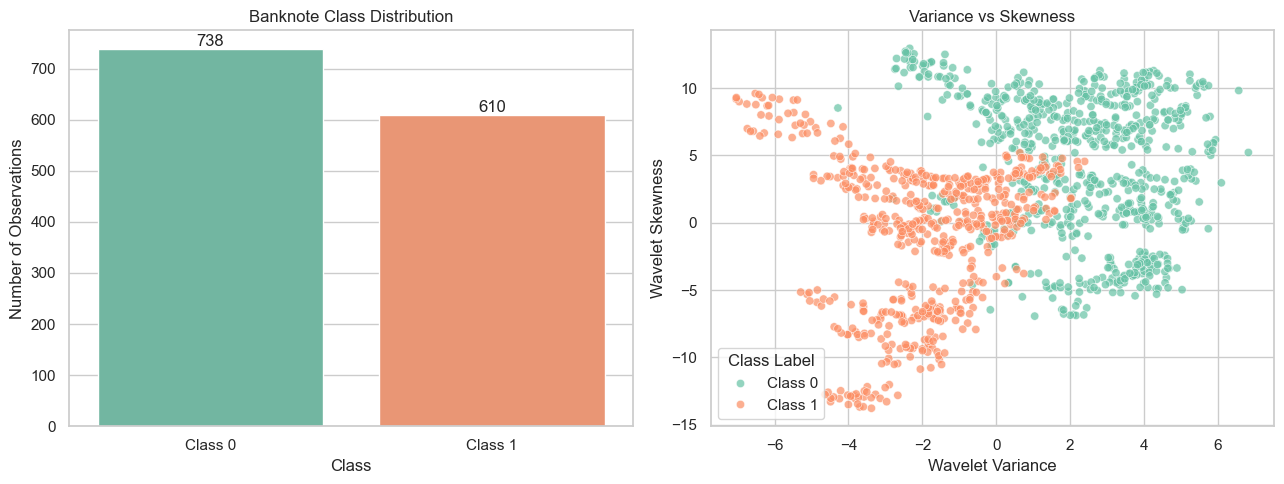

In [25]:
# 5. VISUALIZE CLASS BALANCE AND PAIRWISE STRUCTURE
plot_df = df.copy()
plot_df['Class Label'] = plot_df['class'].map({0: 'Class 0', 1: 'Class 1'})
class_counts = plot_df['Class Label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = sns.barplot(
    x=class_counts.index, y=class_counts.values,
    hue=class_counts.index, legend=False, ax=axes[0]
)
for container in ax.containers:
    ax.bar_label(container)
axes[0].set_title('Banknote Class Distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of Observations')

sns.scatterplot(
    data=plot_df, x='variance', y='skewness',
    hue='Class Label', alpha=0.70, ax=axes[1]
)
axes[1].set_title('Variance vs Skewness')
axes[1].set_xlabel('Wavelet Variance')
axes[1].set_ylabel('Wavelet Skewness')

plt.tight_layout()
plt.show()

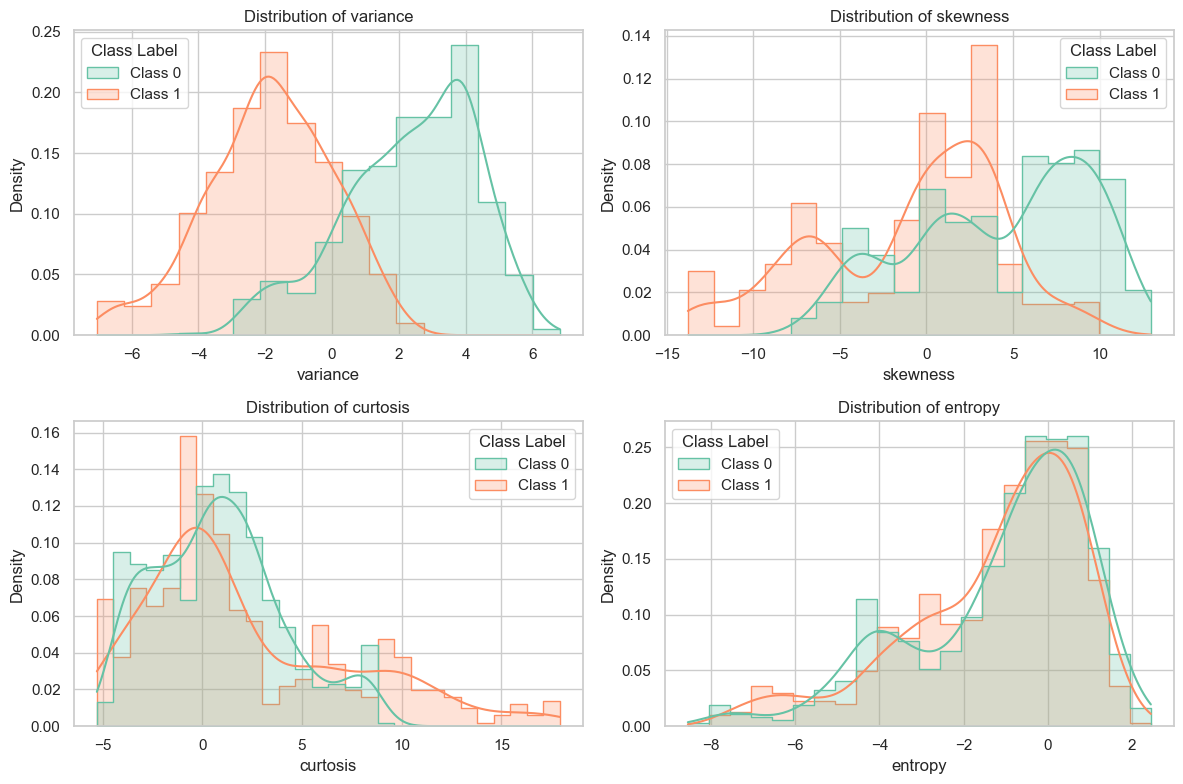

In [26]:
# 6. VISUALIZE FEATURE DISTRIBUTIONS
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(feature_columns, axes.ravel()):
    sns.histplot(
        data=plot_df, x=feature, hue='Class Label', kde=True,
        element='step', stat='density', common_norm=False, ax=ax
    )
    ax.set_title(f'Distribution of {feature}')
plt.tight_layout()
plt.show()

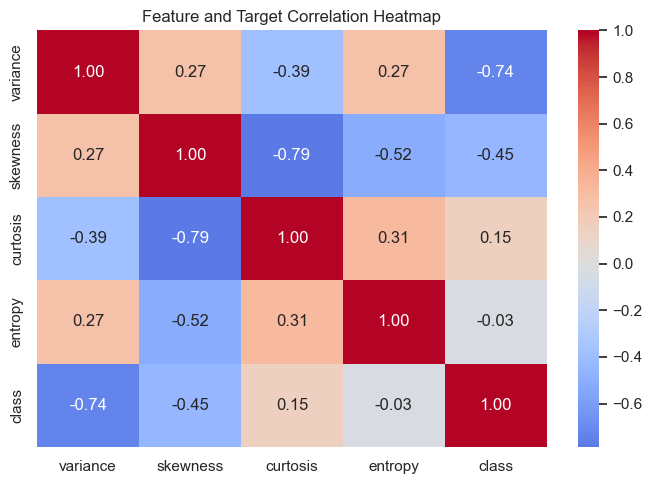

In [27]:
# 7. VISUALIZE FEATURE CORRELATIONS
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature and Target Correlation Heatmap')
plt.tight_layout()
plt.show()

In [28]:
# 8. CREATE STRATIFIED TRAINING AND TEST SETS
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print('Training set:', X_train.shape)
print('Testing set:', X_test.shape)
print('\nTraining class proportions:\n', y_train.value_counts(normalize=True).sort_index().round(4))
print('\nTesting class proportions:\n', y_test.value_counts(normalize=True).sort_index().round(4))

Training set: (1078, 4)
Testing set: (270, 4)

Training class proportions:
 class
0    0.5473
1    0.4527
Name: proportion, dtype: float64

Testing class proportions:
 class
0    0.5481
1    0.4519
Name: proportion, dtype: float64


In [29]:
# 9. IMPLEMENT BASELINE NONLINEAR SVM KERNELS
kernel_names = ['poly', 'rbf', 'sigmoid']
baseline_models = {}
baseline_rows = []

for kernel_name in kernel_names:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(kernel=kernel_name, C=1.0, gamma='scale'))
    ])
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_score = model.decision_function(X_test)
    baseline_models[kernel_name] = model

    baseline_rows.append({
        'Kernel': kernel_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score),
        'Support Vectors': int(model.named_steps['svc'].n_support_.sum())
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    'F1-score', ascending=False
).reset_index(drop=True)
display(baseline_results.round(4))

,Kernel,Accuracy,Precision,Recall,F1-score,ROC-AUC,Support Vectors
0,rbf,0.9963,0.9919,1.0000,0.9959,1.0000,81
1,poly,0.9889,0.9760,1.0000,0.9879,0.9988,264
2,sigmoid,0.7704,0.7206,0.8033,0.7597,0.9000,252


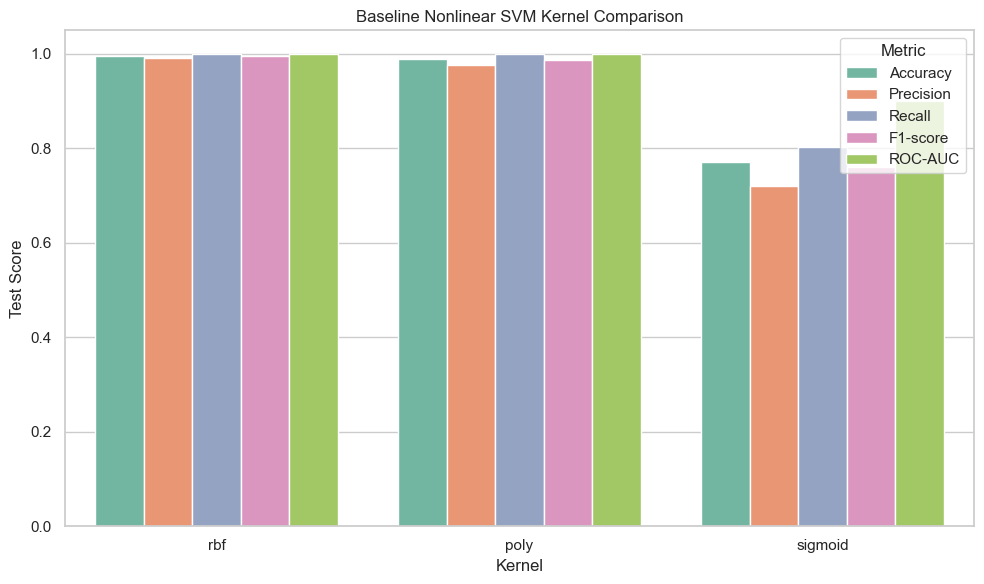

In [30]:
# 10. VISUALIZE BASELINE KERNEL COMPARISON
baseline_long = baseline_results.melt(
    id_vars='Kernel',
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    var_name='Metric', value_name='Score'
)

plt.figure(figsize=(10, 6))
sns.barplot(data=baseline_long, x='Kernel', y='Score', hue='Metric')
plt.ylim(0, 1.05)
plt.title('Baseline Nonlinear SVM Kernel Comparison')
plt.ylabel('Test Score')
plt.tight_layout()
plt.show()

In [31]:
# 11. DEFINE KERNEL-SPECIFIC HYPERPARAMETER GRIDS
kernel_parameter_grids = {
    'poly': {
        'svc__C': [0.1, 1, 10],
        'svc__gamma': ['scale', 0.1, 1],
        'svc__degree': [2, 3, 4],
        'svc__coef0': [0.0, 1.0]
    },
    'rbf': {
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 0.01, 0.1, 1]
    },
    'sigmoid': {
        'svc__C': [0.1, 1, 10],
        'svc__gamma': ['scale', 0.01, 0.1],
        'svc__coef0': [-1.0, 0.0, 1.0]
    }
}

for kernel_name, parameter_grid in kernel_parameter_grids.items():
    combinations = int(np.prod([len(values) for values in parameter_grid.values()]))
    print(f'{kernel_name:<7}: {combinations} hyperparameter combinations')

poly   : 54 hyperparameter combinations
rbf    : 16 hyperparameter combinations
sigmoid: 27 hyperparameter combinations


In [32]:
# 12. TUNE EACH NONLINEAR KERNEL WITH FIVE-FOLD GRID SEARCH
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}
tuned_models = {}
tuning_summary_rows = []
all_cv_results = []

for kernel_name in kernel_names:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(kernel=kernel_name))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=kernel_parameter_grids[kernel_name],
        scoring='f1',
        cv=cv_strategy,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )
    search.fit(X_train, y_train)

    searches[kernel_name] = search
    tuned_models[kernel_name] = search.best_estimator_
    tuning_summary_rows.append({
        'Kernel': kernel_name,
        'Best CV F1-score': search.best_score_,
        'Best Parameters': search.best_params_
    })

    kernel_cv = pd.DataFrame(search.cv_results_)
    kernel_cv['Kernel'] = kernel_name
    all_cv_results.append(kernel_cv)

    print(f'\n{kernel_name.upper()} kernel')
    print('Best parameters:', search.best_params_)
    print('Best mean CV F1-score:', round(search.best_score_, 4))

tuning_summary = pd.DataFrame(tuning_summary_rows).sort_values(
    'Best CV F1-score', ascending=False
).reset_index(drop=True)
display(tuning_summary)


POLY kernel
Best parameters: {'svc__C': 0.1, 'svc__coef0': 1.0, 'svc__degree': 4, 'svc__gamma': 1}
Best mean CV F1-score: 1.0

RBF kernel
Best parameters: {'svc__C': 10, 'svc__gamma': 'scale'}
Best mean CV F1-score: 1.0

SIGMOID kernel
Best parameters: {'svc__C': 10, 'svc__coef0': 0.0, 'svc__gamma': 0.01}
Best mean CV F1-score: 0.9909


,Kernel,Best CV F1-score,Best Parameters
0,poly,1.000000,"{'svc__C': 0.1, 'svc__coef0': 1.0, 'svc__degre..."
1,rbf,1.000000,"{'svc__C': 10, 'svc__gamma': 'scale'}"
2,sigmoid,0.990914,"{'svc__C': 10, 'svc__coef0': 0.0, 'svc__gamma'..."


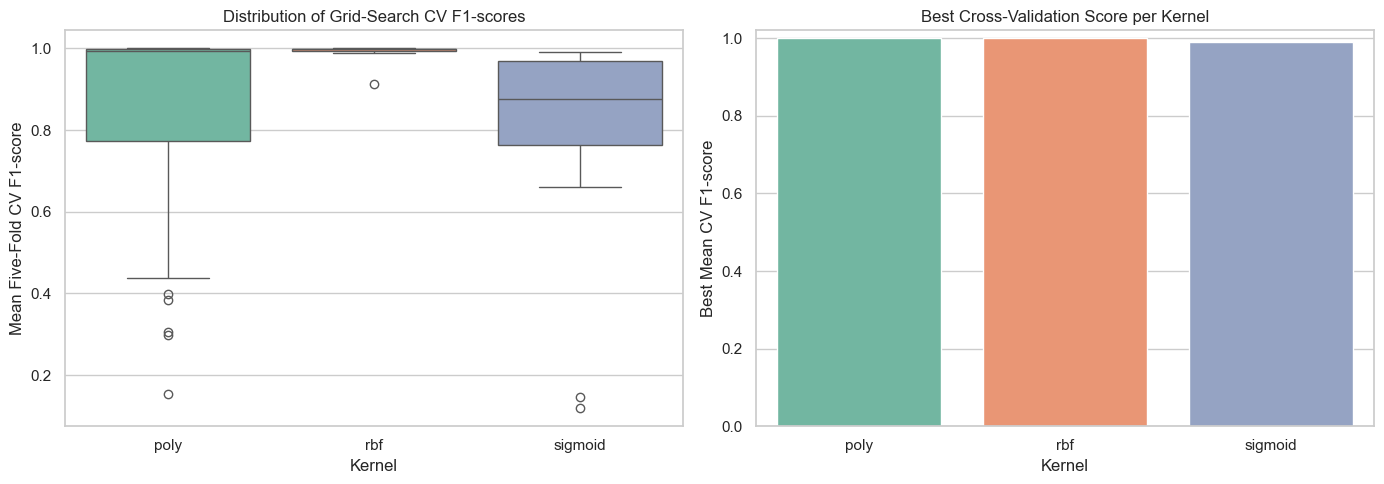

In [33]:
# 13. VISUALIZE CROSS-VALIDATION PERFORMANCE
combined_cv_results = pd.concat(all_cv_results, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=combined_cv_results, x='Kernel', y='mean_test_score',
    hue='Kernel', legend=False, ax=axes[0]
)
axes[0].set_title('Distribution of Grid-Search CV F1-scores')
axes[0].set_xlabel('Kernel')
axes[0].set_ylabel('Mean Five-Fold CV F1-score')

sns.barplot(
    data=tuning_summary, x='Kernel', y='Best CV F1-score',
    hue='Kernel', legend=False, ax=axes[1]
)
axes[1].set_ylim(0, 1.02)
axes[1].set_title('Best Cross-Validation Score per Kernel')
axes[1].set_ylabel('Best Mean CV F1-score')

plt.tight_layout()
plt.show()

In [34]:
# 14. EVALUATE EACH TUNED KERNEL ON THE UNSEEN TEST SET
tuned_rows = []
kernel_predictions = {}
kernel_scores = {}

for kernel_name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_score = model.decision_function(X_test)
    kernel_predictions[kernel_name] = y_pred
    kernel_scores[kernel_name] = y_score

    tuned_rows.append({
        'Kernel': kernel_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score),
        'Support Vectors': int(model.named_steps['svc'].n_support_.sum())
    })

tuned_results = pd.DataFrame(tuned_rows).sort_values(
    'F1-score', ascending=False
).reset_index(drop=True)
display(tuned_results.round(4))

,Kernel,Accuracy,Precision,Recall,F1-score,ROC-AUC,Support Vectors
0,poly,1.0000,1.0000,1.0,1.0000,1.0000,29
1,rbf,1.0000,1.0000,1.0,1.0000,1.0000,32
2,sigmoid,0.9852,0.9683,1.0,0.9839,0.9999,128


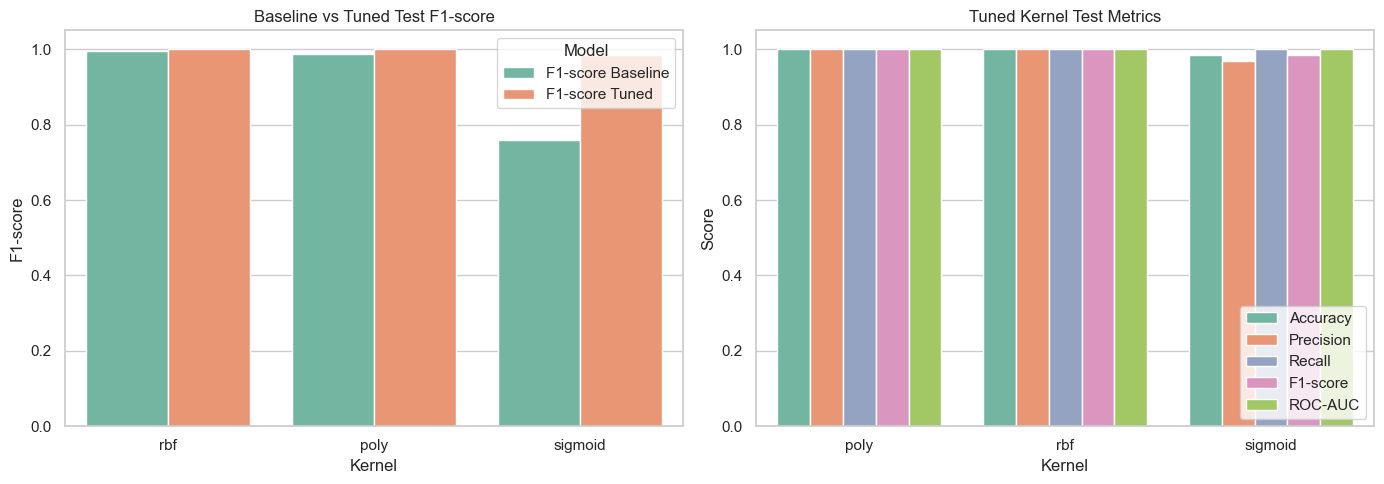

In [35]:
# 15. COMPARE BASELINE AND TUNED KERNELS
comparison = baseline_results[['Kernel', 'F1-score']].merge(
    tuned_results[['Kernel', 'F1-score']],
    on='Kernel', suffixes=(' Baseline', ' Tuned')
)
comparison_long = comparison.melt(
    id_vars='Kernel', var_name='Model', value_name='F1-score'
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=comparison_long, x='Kernel', y='F1-score', hue='Model', ax=axes[0]
)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Baseline vs Tuned Test F1-score')

tuned_long = tuned_results.melt(
    id_vars='Kernel',
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    var_name='Metric', value_name='Score'
)
sns.barplot(data=tuned_long, x='Kernel', y='Score', hue='Metric', ax=axes[1])
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Tuned Kernel Test Metrics')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

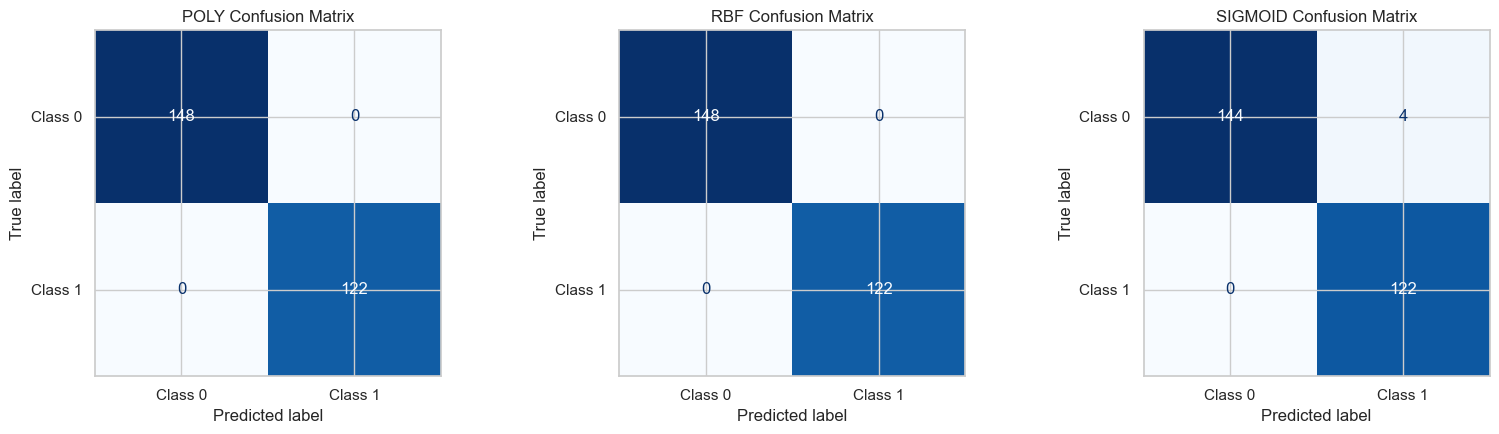

In [36]:
# 16. VISUALIZE CONFUSION MATRICES FOR ALL TUNED KERNELS
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for kernel_name, ax in zip(kernel_names, axes):
    ConfusionMatrixDisplay.from_predictions(
        y_test, kernel_predictions[kernel_name],
        display_labels=['Class 0', 'Class 1'],
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(f'{kernel_name.upper()} Confusion Matrix')

plt.tight_layout()
plt.show()

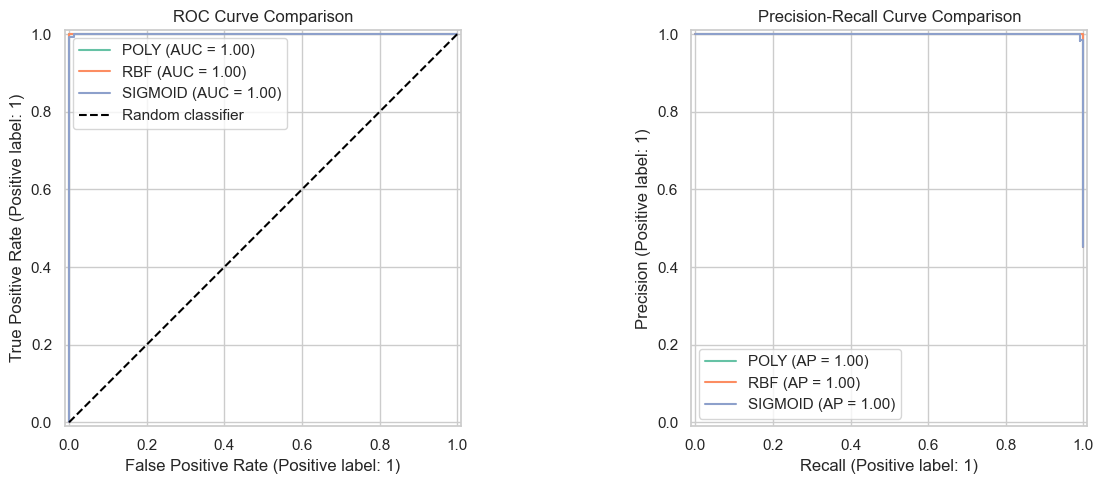

In [37]:
# 17. COMPARE ROC AND PRECISION-RECALL CURVES
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for kernel_name in kernel_names:
    RocCurveDisplay.from_predictions(
        y_test, kernel_scores[kernel_name],
        name=kernel_name.upper(), ax=axes[0]
    )
    PrecisionRecallDisplay.from_predictions(
        y_test, kernel_scores[kernel_name],
        name=kernel_name.upper(), ax=axes[1]
    )

axes[0].plot([0, 1], [0, 1], 'k--', label='Random classifier')
axes[0].set_title('ROC Curve Comparison')
axes[0].legend()
axes[1].set_title('Precision-Recall Curve Comparison')

plt.tight_layout()
plt.show()

In [38]:
# 18. PRINT DETAILED CLASSIFICATION 
for kernel_name in kernel_names:
    print(f'\n--- {kernel_name.upper()} KERNEL ---')
    print('Best parameters:', searches[kernel_name].best_params_)
    print(classification_report(
        y_test, kernel_predictions[kernel_name],
        target_names=['Class 0', 'Class 1'], digits=4
    ))


--- POLY KERNEL ---
Best parameters: {'svc__C': 0.1, 'svc__coef0': 1.0, 'svc__degree': 4, 'svc__gamma': 1}
              precision    recall  f1-score   support

     Class 0     1.0000    1.0000    1.0000       148
     Class 1     1.0000    1.0000    1.0000       122

    accuracy                         1.0000       270
   macro avg     1.0000    1.0000    1.0000       270
weighted avg     1.0000    1.0000    1.0000       270


--- RBF KERNEL ---
Best parameters: {'svc__C': 10, 'svc__gamma': 'scale'}
              precision    recall  f1-score   support

     Class 0     1.0000    1.0000    1.0000       148
     Class 1     1.0000    1.0000    1.0000       122

    accuracy                         1.0000       270
   macro avg     1.0000    1.0000    1.0000       270
weighted avg     1.0000    1.0000    1.0000       270


--- SIGMOID KERNEL ---
Best parameters: {'svc__C': 10, 'svc__coef0': 0.0, 'svc__gamma': 0.01}
              precision    recall  f1-score   support

     Class 0 

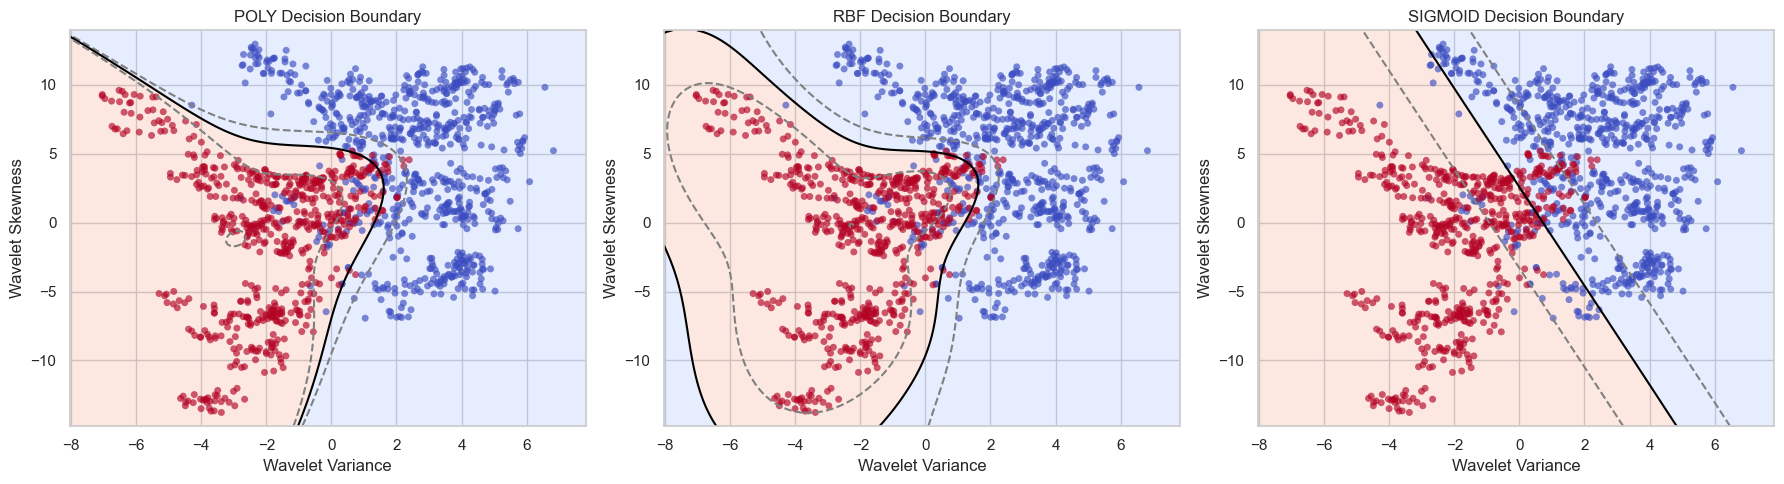

In [39]:
# 19. VISUALIZE NONLINEAR DECISION BOUNDARIES
visual_features = ['variance', 'skewness']
X_visual_train = X_train[visual_features]
X_visual_all = X[visual_features]

x_min, x_max = X_visual_all['variance'].min() - 1, X_visual_all['variance'].max() + 1
y_min, y_max = X_visual_all['skewness'].min() - 1, X_visual_all['skewness'].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350)
)
grid_df = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()], columns=visual_features
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for kernel_name, ax in zip(kernel_names, axes):
    best_svc_parameters = {
        key.replace('svc__', ''): value
        for key, value in searches[kernel_name].best_params_.items()
    }
    visual_model = Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(kernel=kernel_name, **best_svc_parameters))
    ])
    visual_model.fit(X_visual_train, y_train)
    decision_values = visual_model.decision_function(grid_df).reshape(xx.shape)

    ax.contourf(xx, yy, decision_values > 0, alpha=0.22, cmap='coolwarm')
    ax.contour(
        xx, yy, decision_values, levels=[-1, 0, 1],
        colors=['gray', 'black', 'gray'], linestyles=['--', '-', '--']
    )
    ax.scatter(
        X_visual_all['variance'], X_visual_all['skewness'],
        c=y, cmap='coolwarm', edgecolor='none', s=25, alpha=0.65
    )
    ax.set_title(f'{kernel_name.upper()} Decision Boundary')
    ax.set_xlabel('Wavelet Variance')
    ax.set_ylabel('Wavelet Skewness')

plt.tight_layout()
plt.show()

In [40]:
# 20. FINAL SUMMARY
best_kernel = tuned_results.iloc[0]['Kernel']
best_row = tuned_results.iloc[0]

print('Compared kernels:', ', '.join(kernel_names))
print('Best test-set kernel:', best_kernel)
print('Best parameters:', searches[best_kernel].best_params_)
print('Test accuracy:', round(best_row['Accuracy'], 4))
print('Test F1-score:', round(best_row['F1-score'], 4))
print('Test ROC-AUC:', round(best_row['ROC-AUC'], 4))
print('The test set was not used during hyperparameter selection.')

Compared kernels: poly, rbf, sigmoid
Best test-set kernel: poly
Best parameters: {'svc__C': 0.1, 'svc__coef0': 1.0, 'svc__degree': 4, 'svc__gamma': 1}
Test accuracy: 1.0
Test F1-score: 1.0
Test ROC-AUC: 1.0
The test set was not used during hyperparameter selection.
